# How the tactic model works: a walkthrough

This notebook follows one tactical clip from video to prediction. Then it shows how the
model was trained and judged. Each step has a short explanation, then code you can run
and a picture.

**It does not retrain the real model.** That took hours. Instead it reads what training
already saved:

- detections cached in `runs/tactic-cache/`
- the results in `runs/tactic-tcn-final/` (`report.json`, `predictions.csv`, `models/`)

The only training here is one short demo in Step 5, about 2 minutes. Running every cell
takes about 3 minutes.

**To run it:** open it in VS Code, choose the `.venv` kernel (top right, "Select
Kernel"), then "Run All".

All the real code lives in the `stratscout/` modules. This notebook only calls it:

| Step | Module |
|---|---|
| Dataset and features | [`stratscout/tactic_features.py`](../stratscout/tactic_features.py) |
| Model, training, cross-validation, report | [`stratscout/tactic_tcn.py`](../stratscout/tactic_tcn.py) |
| Predicting new clips | [`stratscout/tactic_predict.py`](../stratscout/tactic_predict.py) |

## The big picture

The task: given one clip, cut by a person from the start to the end of one tactic on
Mirage, say which of five tactics it is.

| Class | Meaning |
|---|---|
| `A_DIRECT` | Ts commit to A through ramp and/or palace, with no attack through mid → connector |
| `B_DIRECT` | Ts commit to B through apartments, with no attack through mid → short |
| `A_SPLIT` | Ramp/palace attack combined with an attack from mid through connector |
| `B_SPLIT` | Apartments attack combined with an attack from mid through short |
| `RETAKE` | after a confirmed plant, CTs try to regain the site (success not required) |

The full rules are in [`docs/tactic-definitions.md`](../docs/tactic-definitions.md).

The pipeline, from recording to answer:

```
replay recording
   │  prepare-video       crop the spectator radar, fix the 2x replay speed, 10 fps
   ▼
prepared radar video
   │  label-segments      people mark where each tactic starts and ends, and its class
   ▼
labelled segments
   │  export-segments     cut each segment into its own clip; whole matches go to train or test
   ▼
clips/<class>/*.mp4  ───────────────────────────────── this notebook starts here
   │  Step 2  detection   find T dots, CT dots and the bomb on every frame
   │  Step 3  features    141 numbers per time step: where each team is, the bomb, the time
   │  Step 4  TCN         a 1-D convolutional network reads the sequence and outputs 5 scores
   │  Step 5  training    adjust the weights so the right class gets the highest score
   │  Step 6  cross-val   judge settings on matches the model has never seen
   │  Step 7  metrics     precision, recall, F1, confusion matrix
   ▼
Step 8  final models → test set (scored once) → predict-tactics on new clips
```

In [1]:
# Setup: run from the repository root so the relative paths work.
import json
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from stratscout.config import TACTIC_CLASSES
from stratscout.tactic_features import cached_detections, clip_features, feature_dim, load_dataset
from stratscout.tactic_tcn import (
    TacticConfig,
    _eval_features,
    build_model,
    class_weights,
    classification_metrics,
    cross_fold_choice,
    predict,
    receptive_field,
    train_model,
)

DATASET = Path("data/processed/datasets/2026-11-16")
RUN = Path("runs/tactic-tcn-final")
REPORT = json.loads((RUN / "report.json").read_text())

# Colours: T = orange, CT = blue; heatmaps use one blue ramp, light (low) to dark (high).
T_COL, CT_COL, INK, MUTED = "#eb6834", "#2a78d6", "#0b0b0b", "#898781"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)
print("Ready. Working folder:", Path.cwd())

Ready. Working folder: c:\Users\xryan\OneDrive\Documents\GitHub\CV-DL


## Step 1: the dataset

`export-segments` wrote one folder per split, `train/` and `test/`. Each has a
`manifest.csv` listing every clip with its class and match. `load_dataset` reads both.

The key rule: **whole matches go to one side.** All clips from a match are in train, or
all are in test. Clips from the same match look alike: same teams, same observer, same
recording. If one match were split across both sides, the test would partly measure
"have I seen this match before?" instead of "can I recognise the tactic?".

One clip (Spirit #5) is marked `boundary_uncertain`: the labellers weren't sure where
the tactic starts. Training was run with `--exclude-uncertain`, so it's left out here
too.

In [2]:
rows = [r for r in load_dataset(DATASET) if not r["uncertain"]]
table = pd.crosstab(
    [
        pd.Series([r["split"] for r in rows], name="split"),
        pd.Series([r["match"] for r in rows], name="match"),
    ],
    pd.Series([r["label"] for r in rows], name="class"),
)[list(TACTIC_CLASSES)]
table["total"] = table.sum(axis=1)
table

class                                                   A_DIRECT  B_DIRECT  \
split match                                                                  
test  navi-falcons-mirage-cologne-major                       10         3   
      vitality-falcons-mirage-esl-pro-league-season-24         5         3   
train aurora-vitality-mirage-esl-pro-league-season-24          3         3   
      furia-falcons-mirage-cologne-major-2026                  5         5   
      mouz-betboom-mirage-iem-bejing-2026                      4         5   
      spirit-falcons-mirage-cologne-major                      3        11   

class                                                   A_SPLIT  B_SPLIT  \
split match                                                                
test  navi-falcons-mirage-cologne-major                       1        3   
      vitality-falcons-mirage-esl-pro-league-season-24        5        2   
train aurora-vitality-mirage-esl-pro-league-season-24         5        2   
      furia-falcons-mirage-cologne-major-2026                 6        2   
      mouz-betboom-mirage-iem-bejing-2026                     1        3   
      spirit-falcons-mirage-cologne-major                     2        2   

class                                                   RETAKE  total  
split match                                                            
test  navi-falcons-mirage-cologne-major                      7     24  
      vitality-falcons-mirage-esl-pro-league-season-24       6     21  
train aurora-vitality-mirage-esl-pro-league-season-24        6     19  
      furia-falcons-mirage-cologne-major-2026                4     22  
      mouz-betboom-mirage-iem-bejing-2026                    7     20  
      spirit-falcons-mirage-cologne-major                    3     21

Training has four matches (82 clips). Test has two (45 clips). B_SPLIT is the smallest
class, with 9 training clips, so it's the hardest to learn.

## Step 2: detection, from pixels to dots

The model never sees pixels. A hand-written colour-and-shape detector (no learning)
looks at every frame of the radar and finds:

- **players:** position `(x, y)` scaled to 0–1 across the radar, and team (T or CT)
- **the bomb (C4):** whether it's visible, where it is, and whether a player is carrying it

To find player dots, the detector compares each frame with an **empty-map background**:
the median of frames sampled from all of that match's clips. Players move between
frames, so the median keeps only what never changes, which is the map itself.

Detection is the slow part, about 5 seconds per clip. Results are cached in
`runs/tactic-cache/<clip>.npz`, so this notebook reads them instantly.

Below is one training clip: a frame with its detections drawn on top, then every
detection in the clip at once, so you can see the routes.

aurora-vitality-mirage-esl-pro-league-season-24.jx.s001: B_DIRECT, 200 frames at 10 fps = 20.0 s, 1619 player detections


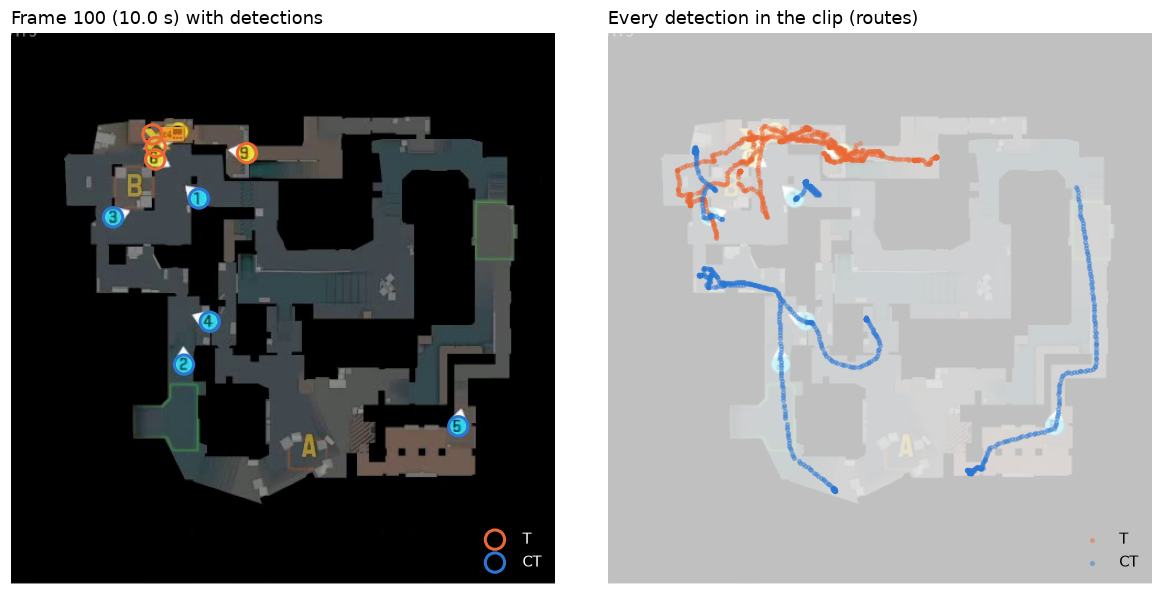

In [3]:
dets = cached_detections(rows, "runs/tactic-cache", log=lambda m: None)
clip = next(
    r
    for r in rows
    if r["clip_id"].endswith("aurora-vitality-mirage-esl-pro-league-season-24.jx.s001")
)
det = dets[clip["clip_id"]]
players = det[
    "players"
]  # one row per detected player per frame: frame, x, y, team (0=T, 1=CT), inferred
n_frames = len(det["bomb"])
print(
    f"{clip['clip_id']}: {clip['label']}, {n_frames} frames at {float(det['fps']):.0f} fps "
    f"= {n_frames / float(det['fps']):.1f} s, {len(players)} player detections"
)

frame_no = n_frames // 2
cap = cv2.VideoCapture(str(clip["path"]))
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no)
ok, bgr = cap.read()
cap.release()
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5.4))
a.imshow(rgb)
here = players[players[:, 0] == frame_no]
for team, col, name in ((0, T_COL, "T"), (1, CT_COL, "CT")):
    p = here[here[:, 3] == team]
    a.scatter(
        p[:, 1] * w, p[:, 2] * h, s=160, facecolors="none", edgecolors=col, linewidths=2, label=name
    )
a.set_title(f"Frame {frame_no} ({frame_no / 10:.1f} s) with detections", loc="left")
a.legend(loc="lower right", labelcolor="white")
a.axis("off")

b.imshow(rgb, alpha=0.25)
for team, col, name in ((0, T_COL, "T"), (1, CT_COL, "CT")):
    p = players[players[:, 3] == team]
    b.scatter(p[:, 1] * w, p[:, 2] * h, s=6, color=col, alpha=0.35, label=name)
b.set_title("Every detection in the clip (routes)", loc="left")
b.legend(loc="lower right")
b.axis("off")
plt.tight_layout()
plt.show()

The detections are **estimates, not ground truth.** Dots that overlap, or sit on top of
the site letters, can be missed or merged. The model has to cope with that noise, which
is one reason Step 5 adds more noise on purpose.

## Step 3: features, from dots to numbers

Dots per frame can't go into a network directly. The number of dots changes from frame
to frame, and the detector can't tell *which* player is which, so there's no stable
"player 1". Instead, `clip_features` turns each time step into **141 fixed numbers**:

| Numbers | What they describe |
|---|---|
| 64 | **T occupancy grid:** the radar cut into an 8×8 grid. Each T dot is spread over the 4 nearest cells (bilinear), so a dot near a cell edge counts partly on both sides. The cells add up to (number of Ts seen) / 5. |
| 64 | **CT occupancy grid:** the same for CTs |
| 2 | Ts seen / 5, CTs seen / 5 |
| 4 | each team's average position (centroid x, y) |
| 2 | each team's spread: how far players are from their centroid, which is large for a split |
| 4 | bomb visible, bomb x, bomb y, bomb carried |
| 1 | elapsed seconds / 30, so the model knows how far into the clip it is |

Clips are 10 fps, and `step=2` keeps every second frame, so there are **5 time steps per
second**. A 20-second clip becomes a 100 × 141 table. Clips are *never stretched* to the
same length: a slow execute stays slow, because speed is part of the tactic.

Below is the T grid at four moments of the clip, then the counts over time.

feature table: (100, 141) = (time steps, numbers per step); feature_dim = 141


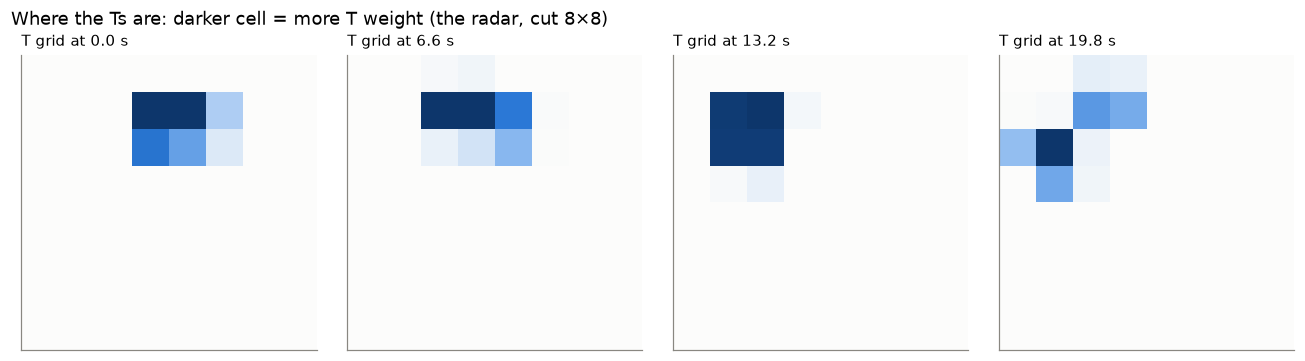

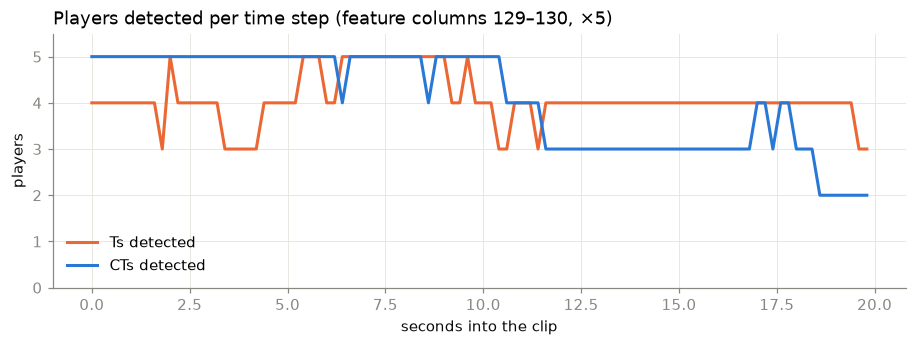

In [4]:
cfg = TacticConfig()  # the settings the real run used
f = clip_features(det, step=cfg.step, grid=cfg.grid)
print(
    "feature table:",
    f.shape,
    "= (time steps, numbers per step); feature_dim =",
    feature_dim(cfg.grid),
)

g2 = cfg.grid**2
moments = np.linspace(0, len(f) - 1, 4).astype(int)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, i in zip(axes, moments):
    ax.imshow(f[i, :g2].reshape(cfg.grid, cfg.grid), cmap=BLUES, vmin=0, vmax=0.2)
    ax.set_title(f"T grid at {i / 5:.1f} s", loc="left", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle(
    "Where the Ts are: darker cell = more T weight (the radar, cut 8×8)", x=0.01, ha="left"
)
plt.tight_layout()
plt.show()

t = np.arange(len(f)) / 5
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, f[:, 2 * g2] * 5, color=T_COL, lw=2, label="Ts detected")
ax.plot(t, f[:, 2 * g2 + 1] * 5, color=CT_COL, lw=2, label="CTs detected")
ax.set_xlabel("seconds into the clip")
ax.set_ylabel("players")
ax.set_ylim(0, 5.5)
ax.set_title("Players detected per time step (feature columns 129–130, ×5)", loc="left")
ax.legend(loc="lower left")
plt.show()

The counts jump around. Some of that is real (players die), and some is detection noise
(overlapping dots). That's why the model gets the whole sequence, not one frame.

**Normalisation.** Before training, every one of the 141 columns is shifted and scaled
to mean 0 and standard deviation 1 over the training clips (`Normaliser`). The mean and
scale are saved with each model, so new clips are scaled the same way.

## Step 4: the model, a residual dilated TCN

A **TCN (temporal convolutional network)** slides small filters along the time axis,
like a CNN slides filters across an image, but in one dimension: time.

```
input  (141 numbers × T steps)
  │  1×1 convolution: mix the 141 numbers into 32 "channels" at every step
  ▼
  5 residual blocks, dilation 1, 2, 4, 8, 16
  │  each block: conv (kernel 3) → LayerNorm → GELU → dropout → conv → LayerNorm → dropout
  │              then add the block's input back on (the "residual" shortcut)
  ▼
  32 channels × T steps
  │  pooling over time: the mean AND the maximum of each channel (→ 64 numbers)
  ▼
  linear layer → 5 scores (one per class) → softmax → 5 probabilities
```

**Why "dilated".** A kernel-3 convolution looks at 3 neighbouring steps. With dilation 2
it looks at steps 2 apart, with dilation 4 at steps 4 apart, and so on. Stacking
dilations 1, 2, 4, 8, 16 lets the last layer see **125 steps = 25 seconds** of context
without needing many layers. The early layers catch quick moves (a fast peek). The later
layers catch slow build-ups (a default that turns into a split).

**Why "residual".** Each block *adds* its change to what it was given. That makes deep
stacks train reliably: a block that has nothing useful to add can learn to pass its
input through unchanged.

**Pooling.** The mean says "on average over the clip, how much of pattern k was there".
The max says "did pattern k happen strongly at any moment". Together they turn a clip of
any length into 64 numbers.

**Padding and masking.** Clips in a batch have different lengths, so short ones are
padded with zeros. A mask zeroes the padding at every layer, so a clip's prediction is
the same whatever it's batched with. A test checks this.

In [5]:
model = build_model("tcn", feature_dim(cfg.grid), cfg)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nLearnable numbers (weights): {n_params:,}")
print("What the conv stack can see after each block:")
for k in range(1, len(cfg.dilations) + 1):
    steps = receptive_field(cfg.kernel, cfg.dilations[:k])
    print(f"  after dilation {cfg.dilations[k - 1]:>2}: {steps:>3} steps = {steps / 5:4.1f} s")

ResidualTCN(
  (inp): Conv1d(141, 32, kernel_size=(1,), stride=(1,))
  (blocks): ModuleList(
    (0): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.2, inplace=False)
    )
    (1): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(2,), dilation=(2,))
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.2, inplace=False)
    )
    (2): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(4,))

**The control model.** `PooledControl` gets the *same* 141 features, but averages and
maxes them over the clip *first*, then uses a small 2-layer network. It can't tell what
happened before what. If the TCN only matched the control, it wouldn't be using the
order of events at all, and we'd have no reason to use a TCN. The control is the test
of that.

## Step 5: training one model

Training repeats one loop many times:

1. **Shuffle** the training clips into batches of 8.
2. **Augment.** Each time a clip is used, it's slightly altered so the model can't memorise exact pixels:
   - start on frame 0 or frame 1 (the `step=2` sampling shifts by one frame)
   - nudge every dot by about 0.5% of the map (`jitter`)
   - drop 5% of detections at random (`drop`), as if the detector missed them
3. **Predict** the 5 probabilities for each clip in the batch.
4. **Loss.** Cross-entropy: a large penalty when the true class gets a low probability.
   It has two adjustments:
   - **class weights:** rare classes count more, so the model can't ignore B_SPLIT (shown below)
   - **label smoothing 0.05:** the target is 95% sure, not 100%, which stops over-confidence
5. **Update.** The AdamW optimiser nudges all the weights to lower the loss, with weight
   decay (a pull towards small weights, against overfitting). The learning rate ramps up
   over the first 5 epochs (warm-up), then stays at 0.001.

One pass over all training clips is an **epoch**. The real run trained up to 150 epochs
and checked the score every 10. Dropout (20%) randomly switches off parts of the network
during training, which is another guard against memorising.

In [6]:
train_rows = [r for r in rows if r["split"] == "train"]
w = class_weights([r["y"] for r in train_rows]).numpy()
pd.DataFrame(
    {
        "training clips": [sum(r["y"] == c for r in train_rows) for c in range(5)],
        "loss weight": w.round(2),
    },
    index=TACTIC_CLASSES,
)

,training clips,loss weight
A_DIRECT,15,1.09
B_DIRECT,24,0.68
A_SPLIT,14,1.17
B_SPLIT,9,1.82
RETAKE,20,0.82


Rare classes get bigger weights: B_SPLIT (9 clips) counts about 2.7 times as much as
B_DIRECT (24 clips).

**Demo.** Train on three matches, hold out Aurora–Vitality, and check the held-out score
every 5 epochs for 30 epochs. This is one fold and one seed of what the real run did 24
times (and for 150 epochs). It takes about 2 minutes.

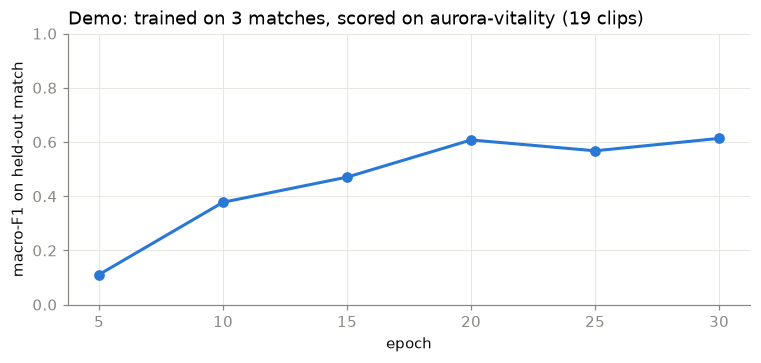

held-out macro-F1 by epoch: {5: 0.111, 10: 0.378, 15: 0.47, 20: 0.608, 25: 0.568, 30: 0.613}


In [7]:
held = "aurora-vitality-mirage-esl-pro-league-season-24"
fit = [(dets[r["clip_id"]], r["y"]) for r in train_rows if r["match"] != held]
val = [r for r in train_rows if r["match"] == held]
demo_cfg = TacticConfig(eval_every=5)


def validate(model, norm):
    probs = predict(model, _eval_features([dets[r["clip_id"]] for r in val], norm, demo_cfg))
    return classification_metrics([r["y"] for r in val], probs.argmax(1))["macro_f1"]


_, _, history = train_model("tcn", fit, demo_cfg, seed=0, epochs=30, validate=validate)
epochs, scores = zip(*history)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(epochs, scores, color=CT_COL, lw=2, marker="o", ms=6)
ax.set_xlabel("epoch")
ax.set_ylabel("macro-F1 on held-out match")
ax.set_ylim(0, 1)
ax.set_title(
    f"Demo: trained on 3 matches, scored on {held.split('-mirage')[0]} ({len(val)} clips)",
    loc="left",
)
plt.show()
print("held-out macro-F1 by epoch:", {e: round(s, 3) for e, s in history})

The model never trains on the held-out match. The curve shows how well what it learned
from the other three transfers. It starts near chance and climbs within the first few
dozen epochs.

## Step 6: cross-validation, choosing settings without peeking at the test

We need to decide things like *how many epochs to train*. Deciding them from test
results would make the test score meaningless. So every decision uses only the training
matches, through **leave-one-match-out cross-validation**:

| Fold | Trains on | Scored on |
|---|---|---|
| 1 | Furia, MOUZ, Spirit | Aurora–Vitality |
| 2 | Aurora, MOUZ, Spirit | Furia–Falcons |
| 3 | Aurora, Furia, Spirit | MOUZ–BetBoom |
| 4 | Aurora, Furia, MOUZ | Spirit–Falcons |

Each fold is trained with 3 **seeds** (different random starts and shuffles), because
with this little data one run can be lucky or unlucky. That's 4 folds × 3 seeds = 12
runs per model, each checked every 10 epochs.

**The epoch choice is also held out (the "cross-fold" score).** For each fold, the
epoch is chosen using the *other three* folds' curves, then that fold is scored at that
epoch. That way no match picks its own best epoch. The "optimistic" score (choose the
single best epoch on all folds, then score those same folds) is shown only for
comparison: it's flattered by the choice.

**Final epoch count.** The epoch with the best average over all folds becomes the number
of epochs for the final models (Step 8).

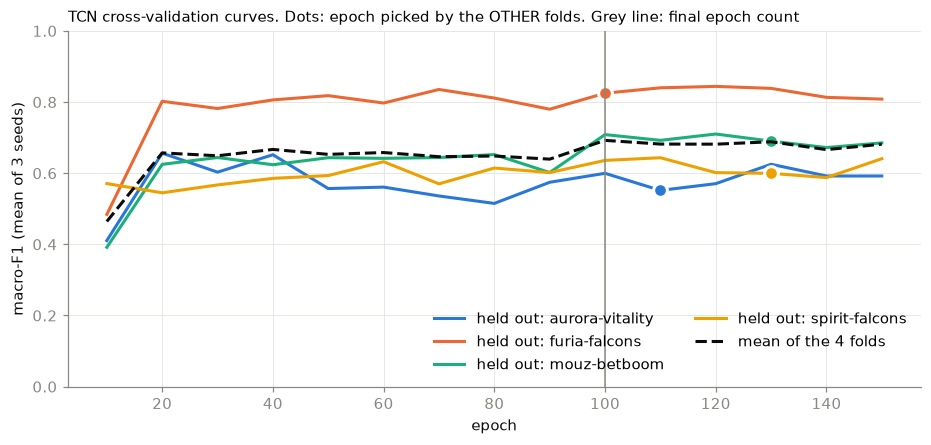

,cross-fold macro-F1,optimistic,final epochs
model,,,
tcn,0.667,0.692,100.0
control,0.625,0.634,20.0
majority (always B_DIRECT),0.065,NaN,NaN


In [8]:
def fold_curves(kind):
    runs = REPORT["models"][kind]["cv_runs"]
    out = {}
    for m in sorted({r["held_out"] for r in runs}):
        hist = np.array([[s for _, s in r["history"]] for r in runs if r["held_out"] == m])
        out[m] = hist.mean(0)  # mean over seeds
    return [e for e, _ in runs[0]["history"]], out


ep, curves = fold_curves("tcn")
chosen = cross_fold_choice(curves)
fig, ax = plt.subplots(figsize=(10, 4.2))
for (m, c), col in zip(curves.items(), SERIES):
    short = m.split("-mirage")[0]
    ax.plot(ep, c, color=col, lw=2, label=f"held out: {short}")
    ax.plot(ep[chosen[m]], c[chosen[m]], "o", ms=9, color=col, mec="white", mew=2)
mean = np.mean(list(curves.values()), 0)
ax.plot(ep, mean, color=INK, lw=2, ls="--", label="mean of the 4 folds")
ax.axvline(REPORT["models"]["tcn"]["cv"]["final_epoch"], color=MUTED, lw=1)
ax.set_xlabel("epoch")
ax.set_ylabel("macro-F1 (mean of 3 seeds)")
ax.set_ylim(0, 1)
ax.set_title(
    "TCN cross-validation curves. Dots: epoch picked by the OTHER folds. Grey line: final epoch count",
    loc="left",
    fontsize=10,
)
ax.legend(loc="lower right", ncol=2)
plt.show()

summary = []
for kind in ("tcn", "control"):
    cv = REPORT["models"][kind]["cv"]
    summary.append(
        {
            "model": kind,
            "cross-fold macro-F1": round(cv["cross_fold_macro_f1"], 3),
            "optimistic": round(cv["optimistic_macro_f1"], 3),
            "final epochs": cv["final_epoch"],
        }
    )
maj = REPORT["majority"]
summary.append(
    {
        "model": f"majority (always {maj['class']})",
        "cross-fold macro-F1": round(
            np.mean([v for k, v in maj.items() if k not in ("test", "class")]), 3
        ),
        "optimistic": None,
        "final epochs": None,
    }
)
pd.DataFrame(summary).set_index("model")

What to take from this:

- **The folds differ a lot** (Furia about 0.8, Aurora–Vitality about 0.55). With only 4
  matches, the true score on a new match is roughly 0.6–0.75.
- **The mean curve is flat after about epoch 20**, so the exact epoch hardly matters and
  training longer wouldn't help. That is also why overfitting from too many epochs isn't
  a concern here.
- **TCN 0.667 > control 0.625 > majority 0.065.** The order of events helps, which
  justifies the TCN.

## Step 7: reading the metrics

For each class:

- **Precision:** of the clips the model *called* this class, the fraction that really
  were. Low precision means false alarms.
- **Recall:** of the clips that *really are* this class, the fraction the model found.
  Low recall means misses.
- **F1:** a single number combining the two (their harmonic mean). It's high only if
  both are high.
- **Macro-F1:** the plain average of the five F1s. Every class counts equally, so a
  model can't score well by being good only at the common classes. This is the main
  number. Accuracy alone would hide a model that never predicts B_SPLIT.

A **confusion matrix** shows every clip: rows are the true class, columns are what the
model said. The diagonal is correct, and everything off it is a mistake.

**Seed ensemble.** The 3 seeds' probabilities are averaged, then the highest is
picked. Averaging smooths out each seed's quirks, which is why the ensemble beats a
single seed (0.735 against 0.675 in cross-validation).

Below: the TCN ensemble in cross-validation (every training clip predicted once, by
models that never saw its match), and on the test set.

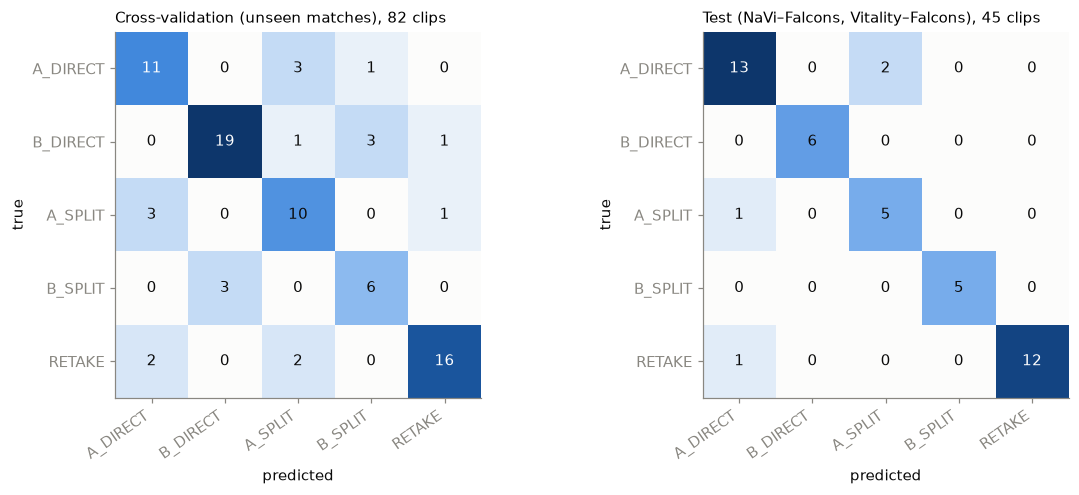

cross-validation                           test                     
                precision recall    f1 support precision recall    f1 support
A_DIRECT             0.69   0.73  0.71    15.0      0.87   0.87  0.87    15.0
B_DIRECT             0.86   0.79  0.83    24.0      1.00   1.00  1.00     6.0
A_SPLIT              0.62   0.71  0.67    14.0      0.71   0.83  0.77     6.0
B_SPLIT              0.60   0.67  0.63     9.0      1.00   1.00  1.00     5.0
RETAKE               0.89   0.80  0.84    20.0      1.00   0.92  0.96    13.0

In [9]:
def confusion_plot(ax, conf, title):
    conf = np.asarray(conf)
    ax.imshow(conf, cmap=BLUES)
    ax.set_xticks(range(5), TACTIC_CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(5), TACTIC_CLASSES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.grid(False)
    for i in range(5):
        for j in range(5):
            v = conf[i, j]
            ax.text(
                j,
                i,
                v,
                ha="center",
                va="center",
                fontsize=10,
                color="white" if v > conf.max() * 0.55 else INK,
            )
    ax.set_title(title, loc="left", fontsize=10)


tcn = REPORT["models"]["tcn"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6))
confusion_plot(
    a, tcn["cv"]["pooled"]["ensemble"]["confusion"], "Cross-validation (unseen matches), 82 clips"
)
confusion_plot(
    b, tcn["test"]["ensemble"]["confusion"], "Test (NaVi–Falcons, Vitality–Falcons), 45 clips"
)
plt.tight_layout()
plt.show()


def per_class(m):
    return pd.DataFrame(m["per_class"]).T[["precision", "recall", "f1", "support"]].round(2)


display(
    pd.concat(
        {
            "cross-validation": per_class(tcn["cv"]["pooled"]["ensemble"]),
            "test": per_class(tcn["test"]["ensemble"]),
        },
        axis=1,
    )
)

**How to read it.** The model almost never gets the **site** wrong: A-tactics are
confused with A-tactics, B with B. Most mistakes are **direct vs split on the same
site**, a handful of retakes get called A-tactics, and in the test table the main
remaining confusion is A_DIRECT vs A_SPLIT.

**Why the test is higher than cross-validation:**

- the test matches share teams with training (Falcons, Vitality)
- the final models had four training matches, not three
- with 5–6 test clips in some classes, one clip moves their F1 by 15–20 points

Report cross-validation as the estimate for new matches, and the test as the held-out
check.

## Step 8: the final models, the test set and predicting

With the settings fixed, `train-tactics --evaluate-test` did the last step **once**:

1. Train on **all four** training matches for the final epoch count (100 for the TCN),
   with seeds 0, 1 and 2.
2. Save each seed in `runs/tactic-tcn-final/models/` (weights, normaliser, settings).
3. Score the two test matches and write `predictions.csv`.

The test is scored once, on purpose. Changing settings after seeing it would quietly
turn the test into more validation data, and its score would stop meaning "unseen".

`predict-tactics` uses those saved models on any prepared clips. Here is the same thing
in code, on the test clips' cached detections. It reproduces `predictions.csv` exactly.

In [10]:
from stratscout.tactic_predict import ensemble_probs, load_ensemble, prediction_rows

members = load_ensemble(RUN / "models", "tcn")
test_rows = [r for r in rows if r["split"] == "test"]
probs = ensemble_probs(members, [dets[r["clip_id"]] for r in test_rows])
pred = pd.DataFrame(
    prediction_rows([r["clip_id"] for r in test_rows], [r["match"] for r in test_rows], probs, 0.6)
)
pred.insert(1, "true", [r["label"] for r in test_rows])

saved = pd.read_csv(RUN / "predictions.csv").query("model == 'tcn'").set_index("clip_id")
p_cols = [f"p_{c}" for c in TACTIC_CLASSES]
diff = np.abs(pred.set_index("clip")[p_cols] - saved.loc[pred["clip"], p_cols]).to_numpy().max()
print(f"{len(members)} seeds loaded; largest difference from predictions.csv: {diff:.4f}")
print(
    f"correct: {(pred['true'] == pred['predicted']).sum()} / {len(pred)}; "
    f"flagged uncertain (top probability < 0.6): {pred['uncertain'].sum()}"
)
pred[pred["true"] != pred["predicted"]][
    ["clip", "true", "predicted", "confidence", "runner_up", "runner_up_p"]
]

3 seeds loaded; largest difference from predictions.csv: 0.0000
correct: 41 / 45; flagged uncertain (top probability < 0.6): 6


,clip,true,predicted,confidence,runner_up,runner_up_p
28,vitality-falcons-mirage-esl-pro-league-season-...,RETAKE,A_DIRECT,0.3891,A_SPLIT,0.3116
32,vitality-falcons-mirage-esl-pro-league-season-...,A_SPLIT,A_DIRECT,0.9213,A_SPLIT,0.0275
38,vitality-falcons-mirage-esl-pro-league-season-...,A_DIRECT,A_SPLIT,0.6381,A_DIRECT,0.2684
42,vitality-falcons-mirage-esl-pro-league-season-...,A_DIRECT,A_SPLIT,0.6279,A_DIRECT,0.3136


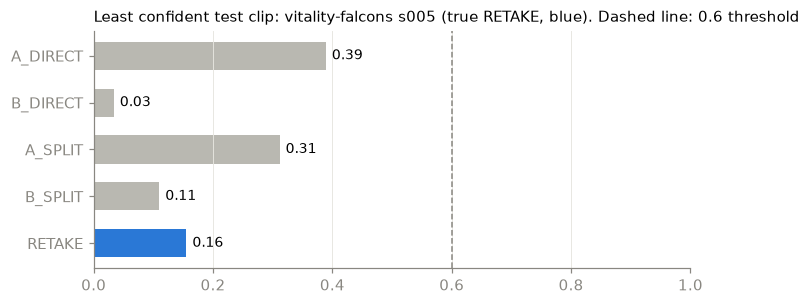

In [11]:
# One flagged clip: the model's probability for each class.
row = pred.sort_values("confidence").iloc[0]
fig, ax = plt.subplots(figsize=(7, 2.8))
vals = [row[f"p_{c}"] for c in TACTIC_CLASSES]
bars = ax.barh(
    TACTIC_CLASSES,
    vals,
    color=[CT_COL if c == row["true"] else "#b9b8b1" for c in TACTIC_CLASSES],
    height=0.6,
)
for bar, v in zip(bars, vals):
    ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(0.6, color=MUTED, ls="--", lw=1)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title(
    f"Least confident test clip: {row['clip'].split('-mirage')[0]} {row['clip'].split('.jx.')[-1]} "
    f"(true {row['true']}, blue). Dashed line: 0.6 threshold",
    loc="left",
    fontsize=10,
)
plt.show()

When no class is clearly ahead, `predict-tactics` marks the clip **uncertain** and shows
the runner-up. Those are the clips worth a human look.

## Glossary

| Term | Meaning |
|---|---|
| clip | one labelled tactic, cut from a round |
| feature | one number describing a time step (141 per step here) |
| epoch | one pass over all training clips |
| batch | the clips used for one weight update (8 here) |
| loss | how wrong the predictions are; training lowers it |
| seed | the random start; different seeds give slightly different models |
| fold | one round of cross-validation with one match held out |
| macro-F1 | the average F1 over the five classes, each counted equally |
| overfitting | learning the training clips too specifically, so new ones do worse |
| ensemble | averaging several models' probabilities |

## Commands

```powershell
# Train and cross-validate (hours); add --evaluate-test only for the final run
.\.venv\Scripts\python.exe -m stratscout train-tactics --dataset data/processed/datasets/2026-11-16 --output runs/<new-folder> --exclude-uncertain --seeds 3

# Classify new prepared clips with the saved models
.\.venv\Scripts\python.exe -m stratscout predict-tactics <clips folder> --output runs/<new-file>.csv
```